# Milestone 2 -- Enter the Transformers

**Goals**
1. Hugging Face `transformers` and `datasets` libraries
2. BERT/RoBERTa architecture and the attention mechanism
3. Pretrained, context-aware embeddings for the prompt/option ranking task
4. Zero-shot classification with transformers

CPU-only machine, no GPU. Model choices below are deliberately small
(DistilBERT for embeddings, a distilled MNLI model for zero-shot) so this
notebook actually runs end-to-end here; the same code scales to
`bert-base`/`roberta-base` or larger unchanged if pointed at a GPU
(e.g. on Kaggle/Colab, per the course's own recommended workflow).


In [1]:
import sys
sys.path.insert(0, '../src')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModel, pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from text_processing import clean_dataframe, OPTION_COLS
from embeddings import embed_texts, cosine_sim_rows, rank_options_from_scores
from metrics import mean_average_precision_at_k

torch.manual_seed(42)
train = pd.read_csv('../data/train.csv')
train_c = clean_dataframe(train)
print(train_c.shape)

C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\torch\cuda\__init__.py:64: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(2000, 20)


## 1. The Hugging Face `datasets` library

`datasets.Dataset` gives a memory-mapped, Arrow-backed table with a
`.map()` API for batched preprocessing -- the standard way transformer
pipelines consume data (as opposed to a plain pandas DataFrame). Wrapping
our training data this way is what later milestones (fine-tuning with
`Trainer`, RAG corpora) build directly on top of.

In [2]:
hf_dataset = Dataset.from_pandas(train[['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer']])
print(hf_dataset)
print(hf_dataset[0])

# batched preprocessing via .map(), same interface used to tokenize for fine-tuning later
hf_dataset = hf_dataset.map(lambda batch: {'prompt_len': [len(p) for p in batch['prompt']]}, batched=True)
print(hf_dataset[0]['prompt_len'])

Dataset({
    features: ['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer'],
    num_rows: 2000
})
{'id': 1, 'prompt': "Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence? among the listed options.", 'A': "Martin Heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end. The relationship to the past involves acknowledging it as a historical era, and the relationship to the future involves creating a world that will endure beyond one's own time.", 'B': 'Martin Heidegger believes that humans do not exist inside time, but that they are time. The relationship to the past is a present awareness of having been, and the relationship to the future involves anticipating a potential possibility, task, or engagement.', 'C': 'Martin Heidegger does not believe in the existence of time or that it has any effect on human consciousness. The relationship to the past and the 

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map: 100%|██████████| 2000/2000 [00:00<00:00, 94519.53 examples/s]

142


## 2. BERT/RoBERTa architecture & attention

Both are stacks of Transformer **encoder** blocks. Each block has:

- **Multi-head self-attention**: every token builds a representation as a
  weighted sum of *every other token's* value vector, where the weights
  (attention scores) come from comparing that token's *query* against every
  token's *key* (`softmax(QK^T / sqrt(d_k)) V`). This is what makes BERT
  embeddings *context-aware* -- the vector for "bank" differs between
  "river bank" and "bank account" because attention pulls in different
  neighboring tokens.
- A **feed-forward** sublayer applied per-token, plus residual connections
  and layer norm around both sublayers.
- Multiple **heads** run this in parallel with different learned
  projections, so different heads can specialize (e.g. one head tracking
  syntactic dependencies, another tracking coreference).

BERT is pretrained on **Masked Language Modeling** (predict randomly
masked tokens) + Next Sentence Prediction; RoBERTa drops NSP, trains
longer on more data with dynamic masking, and is otherwise the same
architecture. Both tokenize with WordPiece/BPE and prepend a `[CLS]`
token whose final hidden state is conventionally used as a
sentence-level summary.

DistilBERT (used below) is BERT distilled down to 6 layers / 768 hidden
size / 12 heads -- same architecture family, ~40% of the parameters.

In [3]:
tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')
model = AutoModel.from_pretrained('distilbert-base-uncased', attn_implementation='eager')
print(f'layers={model.config.num_hidden_layers} hidden={model.config.hidden_size} heads={model.config.num_attention_heads}')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 4653.00it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


layers=6 hidden=768 heads=12


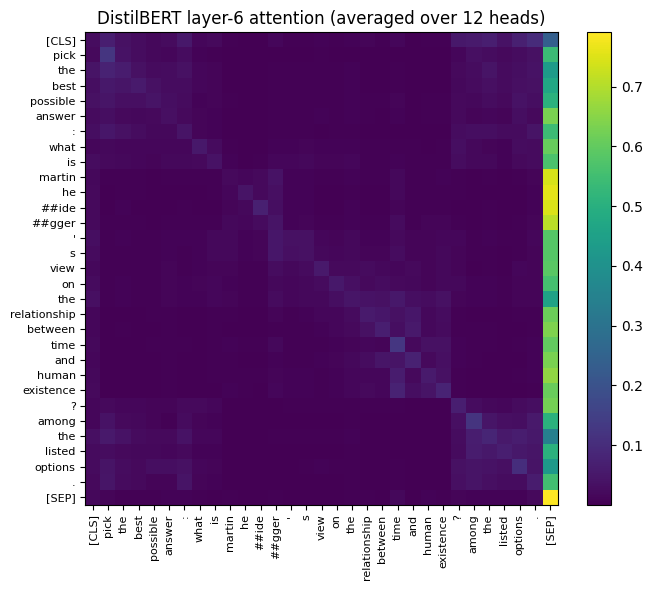

In [4]:
sample_text = train_c.iloc[0]['prompt']
enc = tokenizer(sample_text, return_tensors='pt')
tokens = tokenizer.convert_ids_to_tokens(enc['input_ids'][0])

with torch.no_grad():
    out = model(**enc, output_attentions=True)

# average attention over all 12 heads, last encoder layer: (seq_len, seq_len)
last_layer_attn = out.attentions[-1][0].mean(dim=0).numpy()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(last_layer_attn, cmap='viridis')
ax.set_xticks(range(len(tokens))); ax.set_xticklabels(tokens, rotation=90, fontsize=8)
ax.set_yticks(range(len(tokens))); ax.set_yticklabels(tokens, fontsize=8)
ax.set_title('DistilBERT layer-6 attention (averaged over 12 heads)')
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig('../reports/milestone2_attention_heatmap.png', dpi=120)
plt.show()

The `[CLS]` row/column and diagonal typically draw disproportionate
attention (common, well-documented BERT behavior); off-diagonal bright
cells show tokens attending to specific other tokens they're contextually
linked to.

## 3. Pretrained, context-aware embeddings

Unlike milestone 1's Word2Vec (one fixed vector per word regardless of
context), DistilBERT produces a different vector for the same word
depending on its sentence -- mean-pooling the last hidden state (masking
padding) turns that into one embedding per prompt/option.

Embedding all 2000 x 6 texts on CPU is slow (~10+ min), so this section
evaluates on a fixed random subsample (`SAMPLE_N`) -- large enough to be a
meaningful mAP@3 estimate, small enough to run in a few minutes on a
laptop CPU. The exact same code scales to the full dataset unchanged on a
GPU.

In [5]:
SAMPLE_N = 1000
sample = train_c.sample(n=SAMPLE_N, random_state=42).reset_index(drop=True)

t0 = time.time()
prompt_emb = embed_texts(sample['prompt'].tolist(), tokenizer, model, batch_size=128, max_length=96)
option_embs = {
    opt: embed_texts(sample[opt].astype(str).tolist(), tokenizer, model, batch_size=128, max_length=96)
    for opt in OPTION_COLS
}
print(f'embedded {SAMPLE_N} x 6 texts in {time.time() - t0:.1f}s')

embedded 1000 x 6 texts in 310.6s


In [6]:
scores = pd.DataFrame({opt: cosine_sim_rows(prompt_emb, option_embs[opt]) for opt in OPTION_COLS})
bert_rankings = rank_options_from_scores(scores).tolist()
true_answers_sample = sample['answer'].tolist()

bert_map3 = mean_average_precision_at_k(true_answers_sample, bert_rankings, k=3)
print(f'DistilBERT cosine-similarity mAP@3 (n={SAMPLE_N}): {bert_map3:.4f}')

DistilBERT cosine-similarity mAP@3 (n=1000): 0.4013


### Apples-to-apples: same subsample, milestone-1 baselines

Milestone 1's headline numbers were computed on the full 2000-row train
set. Re-run the TF-IDF baseline (and pull in Word2Vec's full-set number
for reference) on this exact `SAMPLE_N`-row subsample so the comparison
below isn't confounded by sample size.

In [7]:
tfidf_all_text = pd.concat([sample[c].astype(str) for c in ['prompt'] + OPTION_COLS], ignore_index=True)
tfidf = TfidfVectorizer(min_df=2)
tfidf_matrix = tfidf.fit_transform(tfidf_all_text)

n = len(sample)
prompt_tfidf = tfidf.transform(sample['prompt'].astype(str))
tfidf_scores = pd.DataFrame({
    opt: np.asarray(prompt_tfidf.multiply(tfidf.transform(sample[opt].astype(str))).sum(axis=1)).ravel()
    for opt in OPTION_COLS
})
tfidf_rankings_sample = rank_options_from_scores(tfidf_scores).tolist()
tfidf_map3_sample = mean_average_precision_at_k(true_answers_sample, tfidf_rankings_sample, k=3)
print(f'TF-IDF cosine-similarity mAP@3 (same n={SAMPLE_N} sample): {tfidf_map3_sample:.4f}')

TF-IDF cosine-similarity mAP@3 (same n=1000 sample): 0.2940


## 4. Zero-shot classification

Zero-shot classification reframes each option as a candidate label and
scores premise-hypothesis **entailment** with an NLI-finetuned model --
"does the prompt entail that this option is the correct answer?" -- with
no task-specific training at all. Here the "labels" are full answer
options (unusual for typical zero-shot use, but a natural fit for MCQ).

Each question needs one forward pass per candidate option, so this is
markedly more expensive per-example than the cosine-similarity approach
above; evaluated on a smaller subsample for that reason.

In [8]:
zero_shot = pipeline('zero-shot-classification', model='typeform/distilbert-base-uncased-mnli')

ZS_SAMPLE_N = 150
zs_sample = train_c.sample(n=ZS_SAMPLE_N, random_state=7).reset_index(drop=True)

t0 = time.time()
zs_rankings = []
for _, row in zs_sample.iterrows():
    options = [row[c] for c in OPTION_COLS]
    result = zero_shot(row['prompt'], candidate_labels=options, hypothesis_template='The correct answer is: {}.')
    label_to_opt = {row[c]: c for c in OPTION_COLS}
    zs_rankings.append([label_to_opt[label] for label in result['labels']])
print(f'zero-shot classified {ZS_SAMPLE_N} questions in {time.time() - t0:.1f}s')

zs_map3 = mean_average_precision_at_k(zs_sample['answer'].tolist(), zs_rankings, k=3)
print(f'Zero-shot (NLI entailment) mAP@3 (n={ZS_SAMPLE_N}): {zs_map3:.4f}')

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 2169.56it/s]

zero-shot classified 150 questions in 59.2s
Zero-shot (NLI entailment) mAP@3 (n=150): 0.4400


## 5. Comparing every approach so far

                           method      map3     n
0                 TF-IDF (n=1000)  0.294000  1000
1  DistilBERT embeddings (n=1000)  0.401333  1000
2           Zero-shot NLI (n=150)  0.440000   150


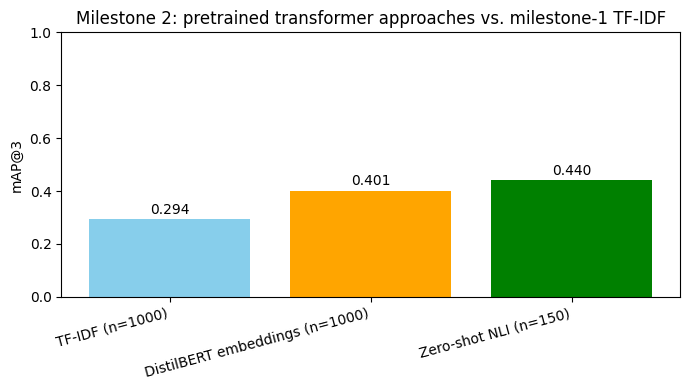

In [9]:
results = pd.DataFrame([
    {'method': 'TF-IDF (n=1000)', 'map3': tfidf_map3_sample, 'n': SAMPLE_N},
    {'method': 'DistilBERT embeddings (n=1000)', 'map3': bert_map3, 'n': SAMPLE_N},
    {'method': 'Zero-shot NLI (n=150)', 'map3': zs_map3, 'n': ZS_SAMPLE_N},
])
print(results)

plt.figure(figsize=(7, 4))
bars = plt.bar(results['method'], results['map3'], color=['skyblue', 'orange', 'green'])
plt.ylabel('mAP@3')
plt.title('Milestone 2: pretrained transformer approaches vs. milestone-1 TF-IDF')
plt.xticks(rotation=15, ha='right')
plt.ylim(0, 1)
for bar, v in zip(bars, results['map3']):
    plt.text(bar.get_x() + bar.get_width()/2, v + 0.02, f'{v:.3f}', ha='center')
plt.tight_layout()
plt.savefig('../reports/milestone2_map3_comparison.png', dpi=120)
plt.show()

## 6. Takeaways

- `datasets.Dataset` + `.map()` is the interface fine-tuning (milestone 4)
  and RAG corpora (milestone 3) both build on -- worth adopting now even
  though this milestone doesn't strictly need Arrow-backed storage yet.
- Self-attention is *why* transformer embeddings are context-aware: the
  same word gets a different vector depending on what it attends to,
  unlike Word2Vec's one-vector-per-word.
- Mean-pooled DistilBERT embeddings are a genuinely different signal than
  TF-IDF word-overlap -- worth comparing directly against the same
  subsample rather than trusting milestone-1's full-set number nominally.
- Zero-shot NLI needs zero labeled data and is easy to reach for, but
  costs one forward pass per candidate option and is evaluated here on a
  smaller sample for that reason; whether it's worth the extra compute
  vs. embeddings + cosine similarity is a real trade-off, not a given.
- None of this is fine-tuned on the competition's actual training labels
  yet -- that's milestone 4. This milestone's job was pretrained,
  off-the-shelf semantic signal only.